In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import scanpy as sc

from preprocess import normalize
from tree_utils import state_tree_draw
from plotting_and_evaluation_metrics import (
    add_embeddings,
    evaluate_scib,
    plot_show_adata,
    plot_umap_embeddings,
    plot_all_pa_scatter,
)

In [2]:
matplotlib.rcdefaults()
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none',
    'savefig.transparent': False,

    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',

    'legend.facecolor': 'white',
    'legend.edgecolor': 'black',
    'legend.frameon':   False,
})

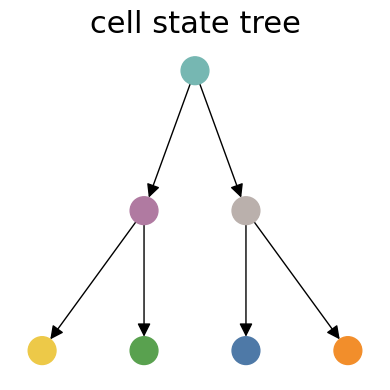

In [3]:
state_tree_draw(state_tree="((t1:2, t2:2):1, (t3:2, t4:2):1):2;", path=Path(f"./results/Figures"))

/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_cluster.pdf


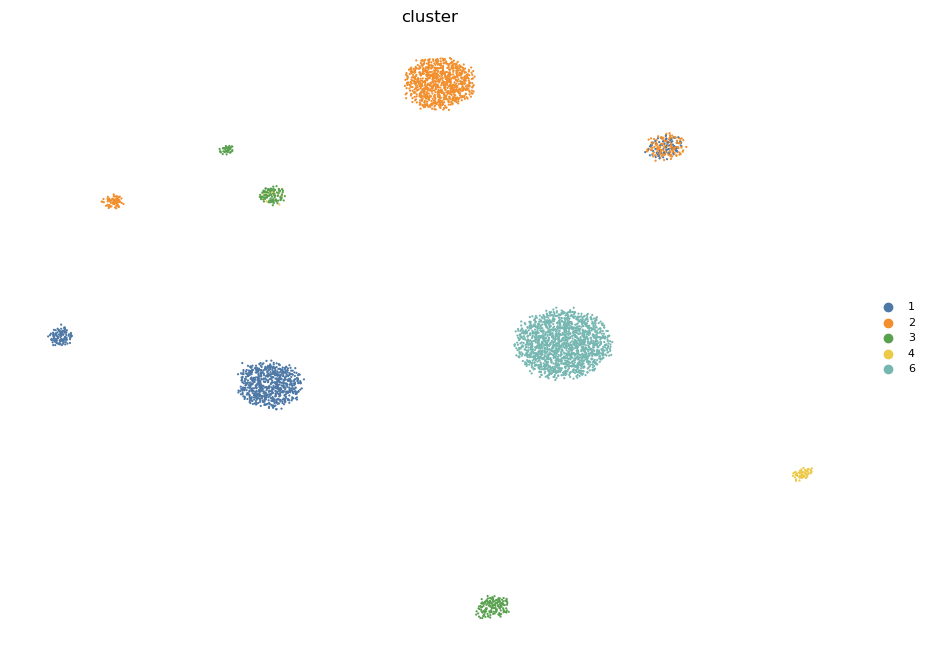

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_subtree.pdf


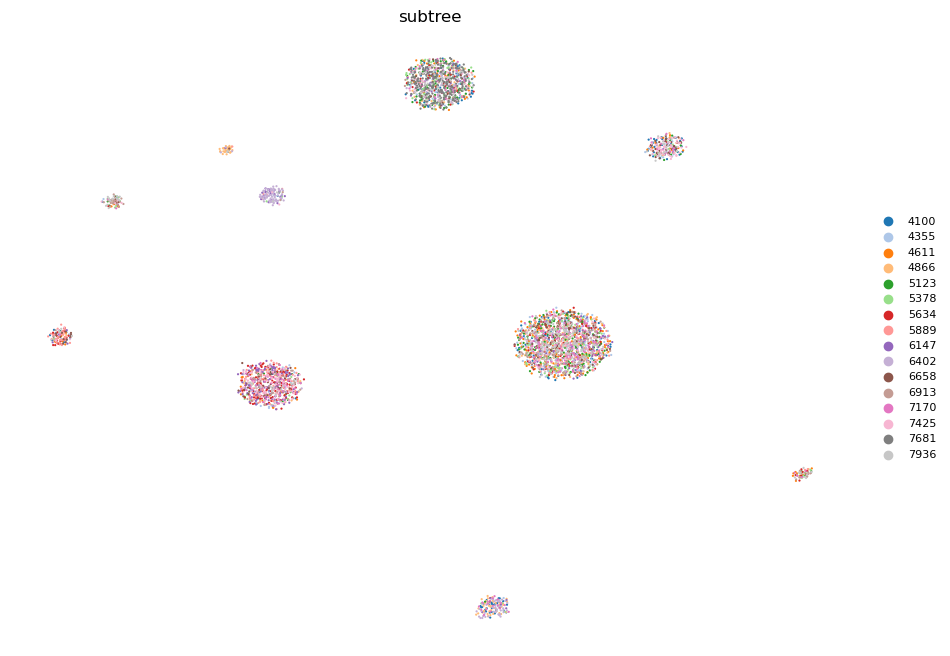

In [4]:
p_a = 0.2

BASE_DIR = Path("./output_data")
output_dir = Path(f"./results/Figures/p_a_{p_a}")
output_dir.mkdir(parents=True, exist_ok=True)

adata = sc.read(BASE_DIR / f"preprocessed_adata_{p_a}.h5ad")
# sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=4000, subset=True)
adata = normalize(adata,
                  size_factors=True,
                  normalize_input=True,
                  logtrans_input=True)

adata.obs['cluster'] = adata.obs['cluster'].astype('category')
adata.obs['subtree'] = adata.obs['subtree'].astype('category')

plot_show_adata(adata, color_feature="cluster", size=10, output_dir=output_dir)
plot_show_adata(adata, color_feature="subtree", size=10, output_dir=output_dir)

Loaded scVI: (4096, 10)
Loaded DeepTracing_UV: (4096, 10)
Loaded DeepTracing_LV: (4096, 5)
Loaded DeepTracing_IV: (4096, 5)
Loaded PORCELAN: (4096, 1000)
Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_UV_cluster.pdf


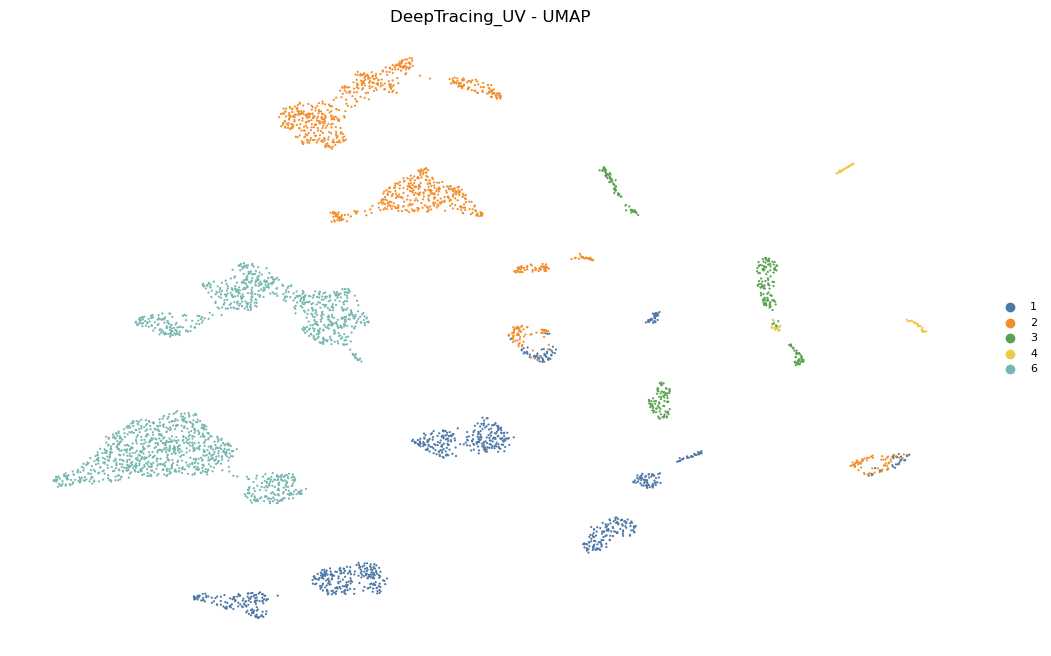

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_UV_subtree.pdf


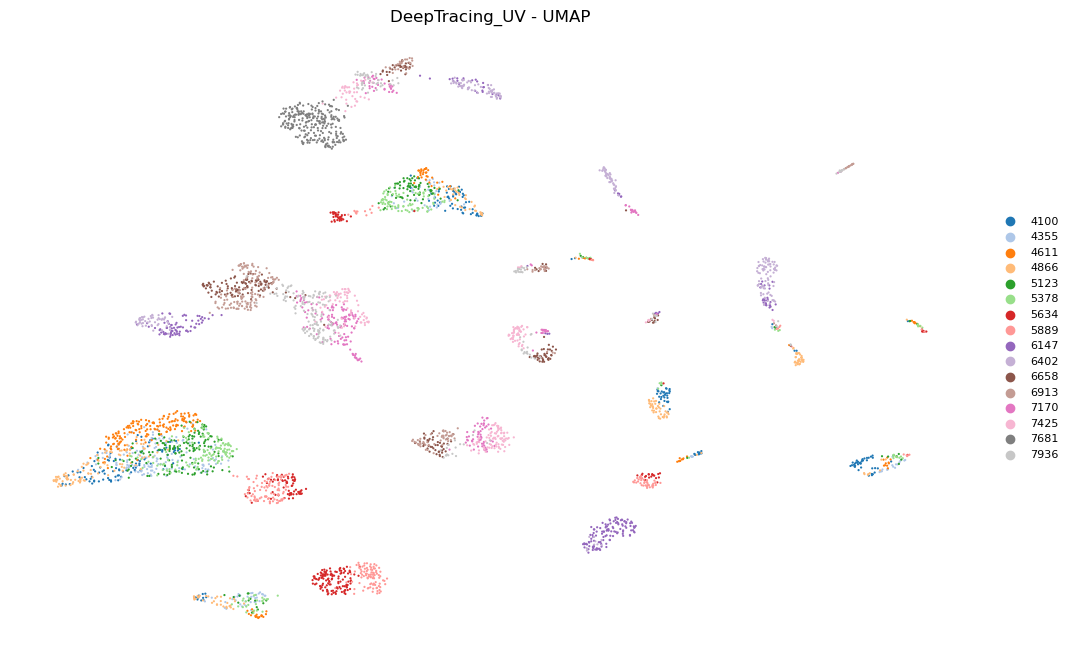

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_LV_cluster.pdf


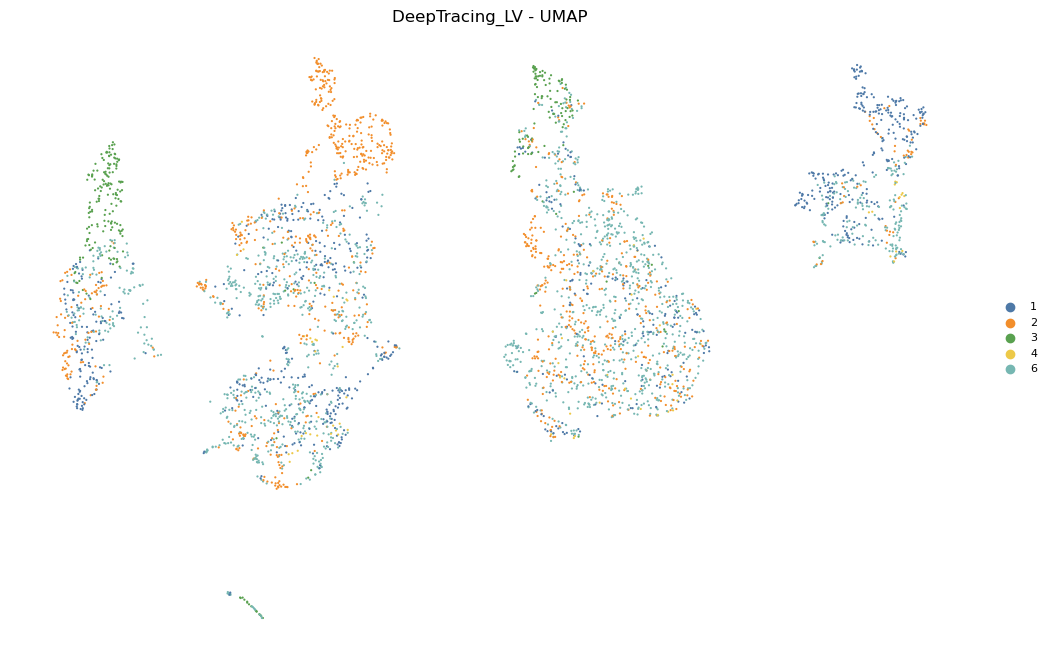

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_LV_subtree.pdf


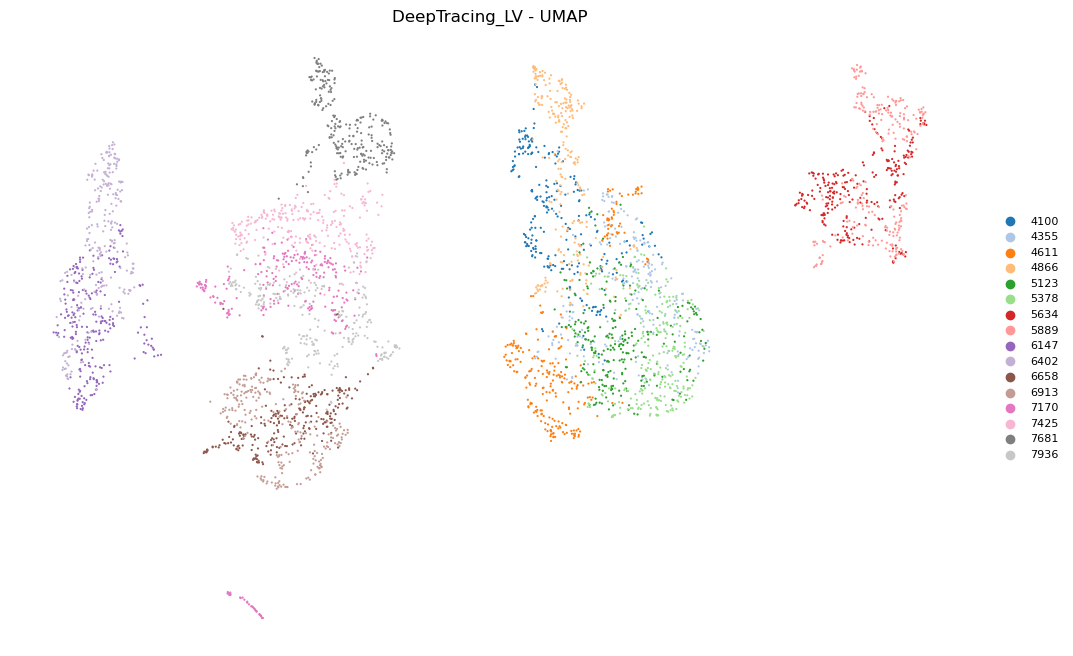

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_IV_cluster.pdf


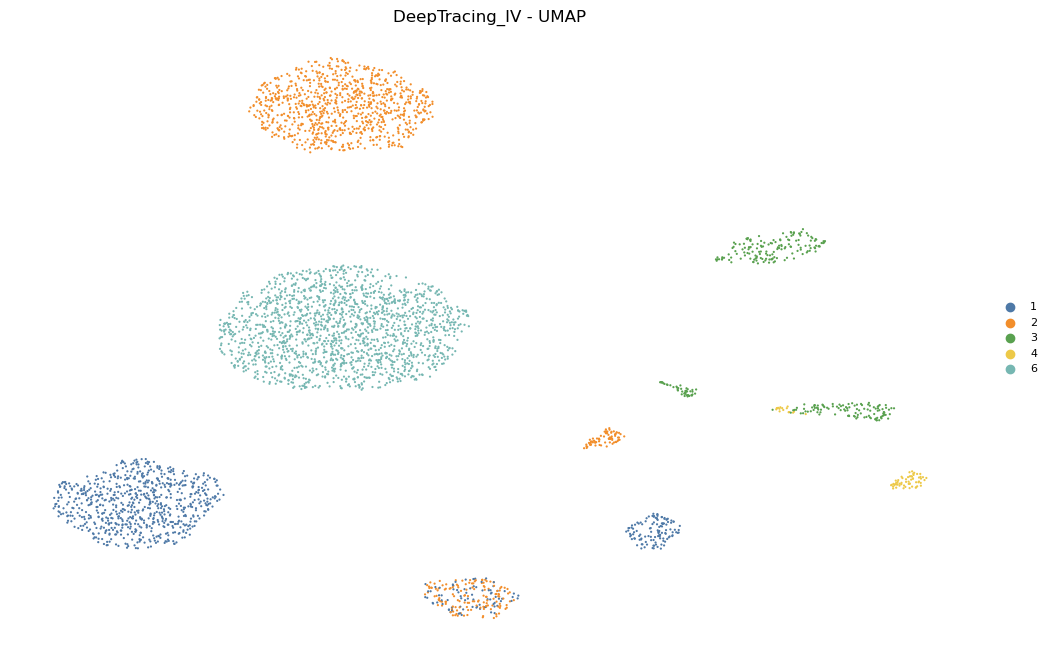

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_DeepTracing_IV_subtree.pdf


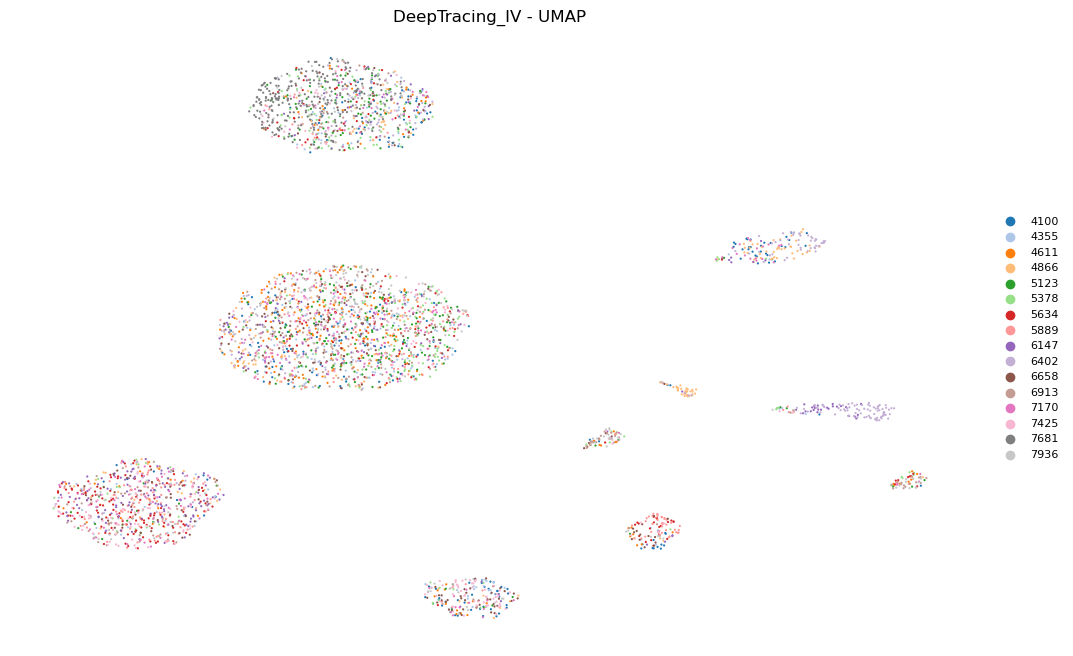

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_scVI_cluster.pdf


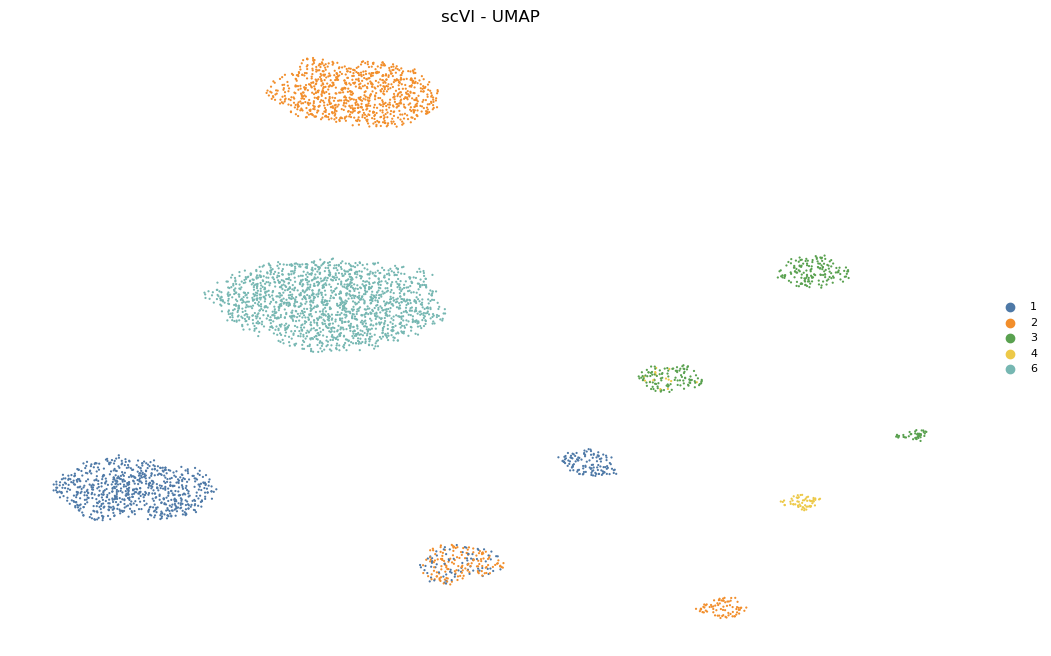

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_scVI_subtree.pdf


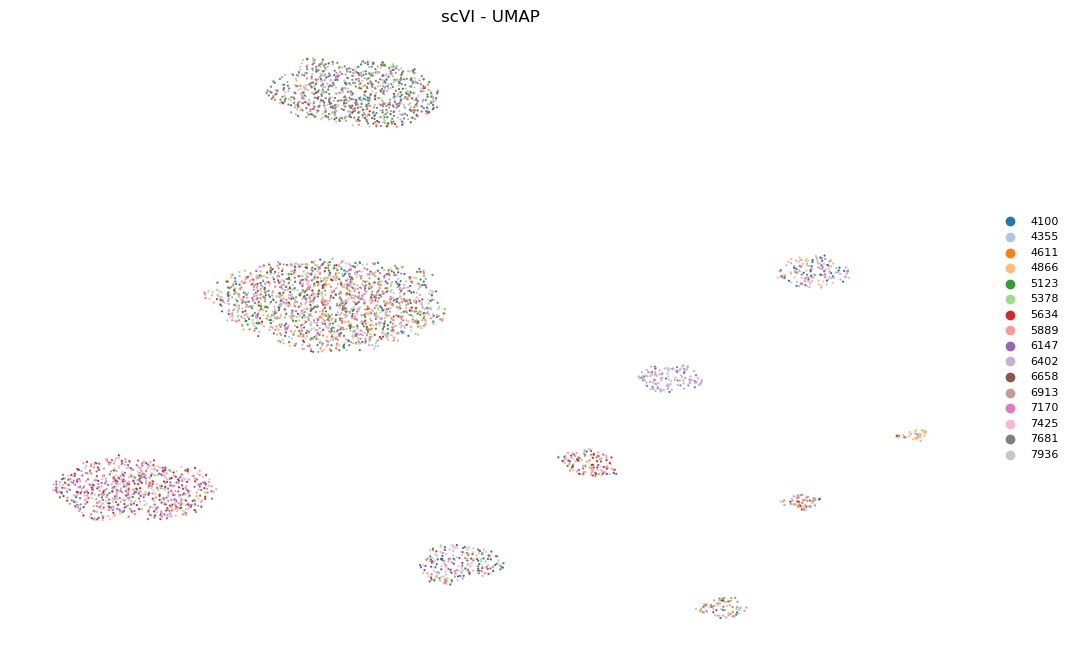

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_PORCELAN_cluster.pdf


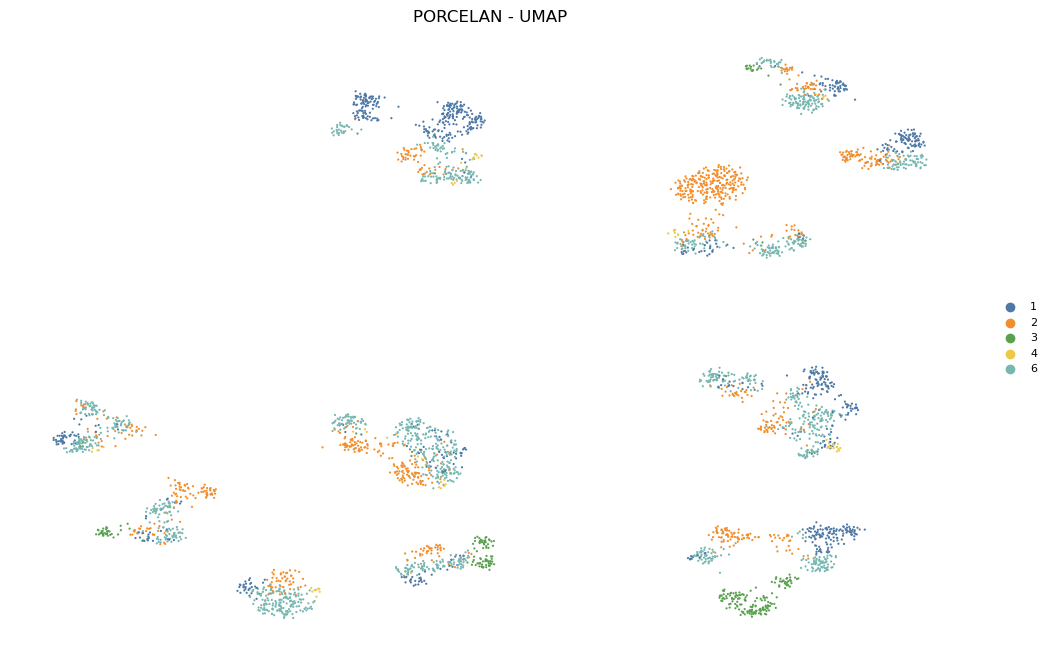

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.2/adata_embeddings_PORCELAN_subtree.pdf


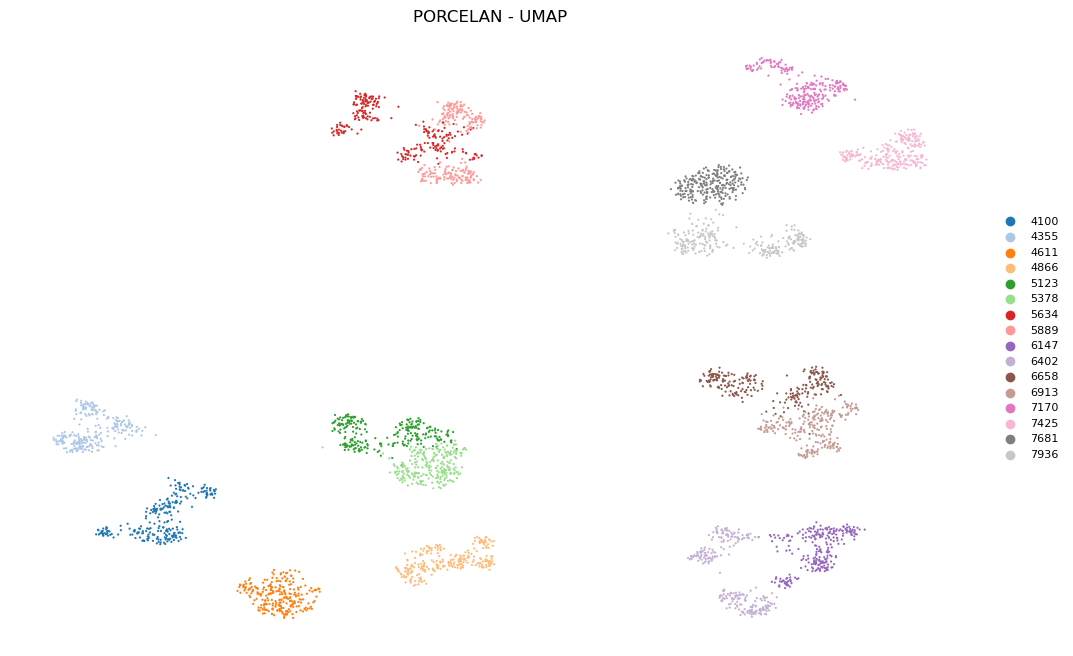

In [5]:
embedding_files = {
        "scVI": f"./results/results_scvi/p_a_{p_a}/scvi_latent_{p_a}.txt",
        "DeepTracing_UV": f"./results/train/p_a_{p_a}/final_latent.txt",
        "DeepTracing_LV": f"./results/train/p_a_{p_a}/gp_latent.txt",
        "DeepTracing_IV": f"./results/train/p_a_{p_a}/gaussian_latent.txt",
        "PORCELAN": f"./TedSim_PORCELAN/results/p_a_{p_a}/TedSim_{p_a}_latent_genes_PORCELAN_1000.npy",
    }
add_embeddings(adata, embedding_files)

plot_umap_embeddings(
    adata,
    rep_keys=["DeepTracing_UV", "DeepTracing_LV", "DeepTracing_IV", "scVI", "PORCELAN"],
    color_keys=["cluster", "subtree"],
    output_dir=output_dir,
)

In [6]:
try:
    print("scib-metrics version:", version("scib-metrics"))
except PackageNotFoundError:
    print("scib-metrics version: unavailable")

P_A_LIST = [0.2, 0.4, 0.6, 0.8]
for P_A in P_A_LIST:
    INPUT_H5AD = (f"./output_data/preprocessed_adata_{P_A}.h5ad")

    OUTPUT_DIR = f"./results/evaluation_metrics/p_a_{P_A}"
    CELL_TYPE_KEY = "cluster"
    CLONE_KEY = "subtree"

    DEEPTRACING_DIR = Path(f"./results/train/p_a_{P_A}")
    SCVI_DIR = Path(f"./results/results_scvi/p_a_{P_A}")
    PORCELAN_DIR = Path(f"./TedSim_PORCELAN/results/p_a_{P_A}")

    EMBEDDING_KEYS = [
        "X_pca",
        "scVI",
        "DeepTracing_UV",
        "DeepTracing_LV",
        "DeepTracing_IV",
        "PORCELAN",
    ]

    EMBEDDING_FILES = {
        "scVI": str(SCVI_DIR / f"scvi_latent_{P_A}.txt"),
        "DeepTracing_UV": str(DEEPTRACING_DIR / f"final_latent.txt"),
        "DeepTracing_LV": str(DEEPTRACING_DIR / f"gp_latent.txt"),
        "DeepTracing_IV": str(DEEPTRACING_DIR / f"gaussian_latent.txt"),
        "PORCELAN": str(PORCELAN_DIR / f"TedSim_{P_A}_latent_genes_PORCELAN_1000.npy"),
    }
    N_JOBS = 8

    adata = sc.read_h5ad(INPUT_H5AD)
    adata = normalize(adata,
                      size_factors=True,
                      normalize_input=True,
                      logtrans_input=True)
    print(adata)
    if "X_pca" not in adata.obsm:
        n_comps = min(50, adata.n_obs - 1, adata.n_vars - 1)
        if n_comps < 1:
            raise ValueError("Not enough cells or genes to compute PCA")
        sc.tl.pca(adata, n_comps=n_comps, random_state=0, svd_solver="arpack")
    print("PCA:", adata.obsm["X_pca"].shape)

    adata = add_embeddings(adata, EMBEDDING_FILES)
    full, summary, benchmarkers = evaluate_scib(
        adata=adata,
        embedding_keys=EMBEDDING_KEYS,
        cell_type_key=CELL_TYPE_KEY,
        clone_key=CLONE_KEY,
        output_dir=OUTPUT_DIR,
        n_jobs=N_JOBS,
    )
    print("\nSummary scores:\n", summary.round(4))
    print(f"\nResults saved under: {OUTPUT_DIR}")

scib-metrics version: 0.5.1
AnnData object with n_obs ﷿﷿﷿﷿﷿﷿ n_vars = 4096 ﷿﷿﷿﷿﷿﷿ 500
    obs: 'time', 'node_depth', 'cluster', 'subtree', 'n_counts', 'size_factors'
    var: 'mean', 'std'
    uns: 'log1p'
    obsm: 'barcodes'
PCA: (4096, 50)
Loaded scVI: (4096, 10)
Loaded DeepTracing_UV: (4096, 10)
Loaded DeepTracing_LV: (4096, 5)
Loaded DeepTracing_IV: (4096, 5)
Loaded PORCELAN: (4096, 1000)

Evaluating Cell Type Conservation...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s, Bio conservation: nmi_ari_cluster_labels_kmeans]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿


Evaluating Clone Conservation...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 6/6 [00:33<00:00,  5.57s/it]o conservation: silhouette_label]

                                                                                          


Summary scores:
                 Cell Type Conservation  Clone Conservation
Embedding                                                 
X_pca                           0.8211              0.2107
scVI                            0.8056              0.2120
DeepTracing_UV                  0.8353              0.3563
DeepTracing_LV                  0.2187              0.5473
DeepTracing_IV                  0.8281              0.1999
PORCELAN                        0.1910              0.7581

Results saved under: ./results/evaluation_metrics/p_a_0.2
AnnData object with n_obs ﷿﷿﷿﷿﷿﷿ n_vars = 4096 ﷿﷿﷿﷿﷿﷿ 500
    obs: 'time', 'node_depth', 'cluster', 'subtree', 'n_counts', 'size_factors'
    var: 'mean', 'std'
    uns: 'log1p'
    obsm: 'barcodes'
PCA: (4096, 50)
Loaded scVI: (4096, 10)
Loaded DeepTracing_UV: (4096, 10)
Loaded DeepTracing_LV: (4096, 5)
Loaded DeepTracing_IV: (4096, 5)
Loaded PORCELAN: (4096, 1000)

Evaluating Cell Type Conservation...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 6/6 [00:21<00:00,  3.66s/it]o conservation: silhouette_label]

                                                                                          

... (7 outputs left out)

Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 6/6 [00:22<00:00,  3.71s/it]o conservation: silhouette_label]

                                                                                          


Evaluating Clone Conservation...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 6/6 [00:31<00:00,  5.22s/it]o conservation: silhouette_label]

                                                                                          


Summary scores:
                 Cell Type Conservation  Clone Conservation
Embedding                                                 
X_pca                           0.4734              0.2364
scVI                            0.4638              0.2321
DeepTracing_UV                  0.5208              0.3999
DeepTracing_LV                  0.4402              0.4050
DeepTracing_IV                  0.6296              0.2472
PORCELAN                        0.2427              0.7393

Results saved under: ./results/evaluation_metrics/p_a_0.8


Axis limits: x=(0.1, 0.9), y=(0.1, 0.9)
p_a=0.2: Clone median=0.2842, Cell Type median=0.8133
Saved: results/evaluation_metrics/scatter_by_pa/conservation_scatter_pa_0.2.svg


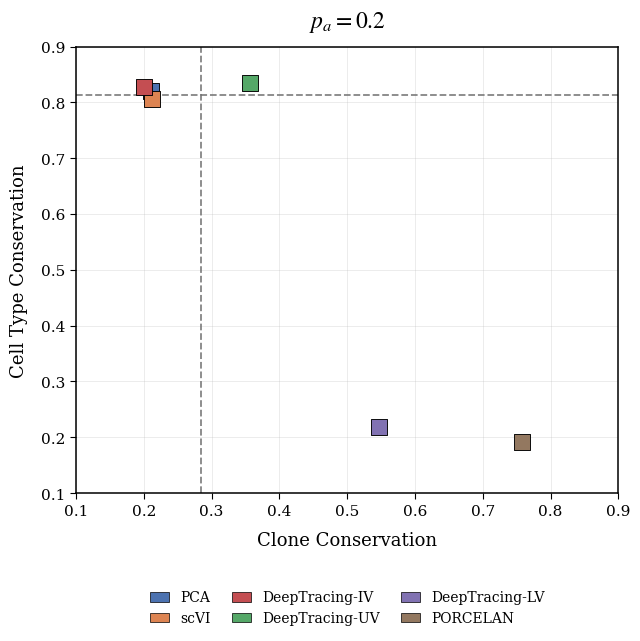

p_a=0.4: Clone median=0.3306, Cell Type median=0.5740
Saved: results/evaluation_metrics/scatter_by_pa/conservation_scatter_pa_0.4.svg


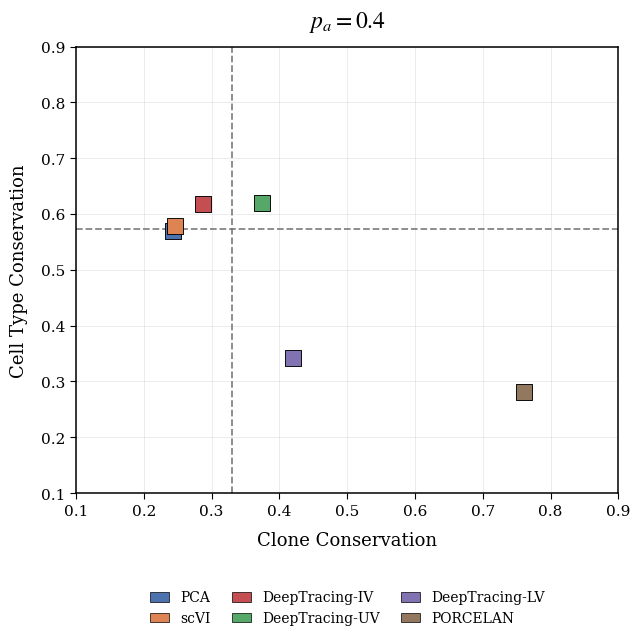

p_a=0.6: Clone median=0.3859, Cell Type median=0.5106
Saved: results/evaluation_metrics/scatter_by_pa/conservation_scatter_pa_0.6.svg


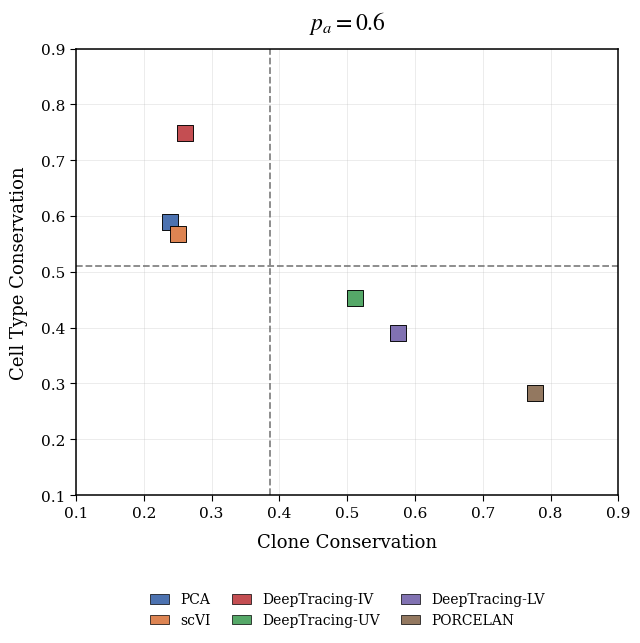

p_a=0.8: Clone median=0.3236, Cell Type median=0.4686
Saved: results/evaluation_metrics/scatter_by_pa/conservation_scatter_pa_0.8.svg


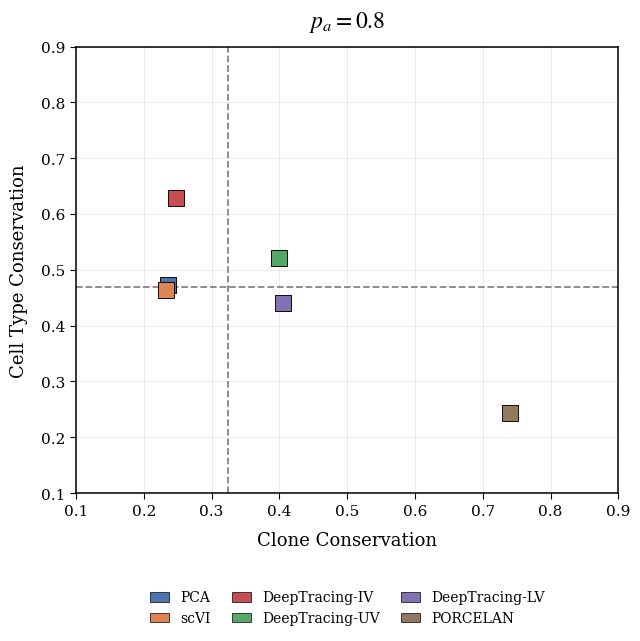

In [7]:
# Four evaluation scatter plots; preserve the original colors, markers, and layout.
scatter_tables = plot_all_pa_scatter(
    base_dir="./results/evaluation_metrics",
    pa_list=P_A_LIST,
    output_dir="./results/evaluation_metrics/scatter_by_pa",
    show=True,
)